# Week 7: Text and Multimodal AI
**Name:** Muhammad Haissam

## Part 1: TF-IDF by Hand

In this section, I calculate TF-IDF weights for three short documents. I use smoothed inverse document frequency and L2 normalization, then compare the second and third documents using cosine similarity.

In [3]:
import math
import numpy as np
from collections import Counter

documents = [
    "win free cash now",
    "call me now",
    "free call now"
]

# Split each document into words
tokenized_docs = [doc.split() for doc in documents]

# Build the vocabulary
vocabulary = sorted(set(word for doc in tokenized_docs for word in doc))
print("Vocabulary:", vocabulary)

# Document frequency: number of documents containing each word
document_frequency = {
    word: sum(word in doc for doc in tokenized_docs)
    for word in vocabulary
}

# Smoothed IDF: ln((1 + number of documents) / (1 + document frequency)) + 1
number_of_documents = len(documents)

idf = {
    word: math.log(
        (1 + number_of_documents) / (1 + document_frequency[word])
    ) + 1
    for word in vocabulary
}

# Calculate TF-IDF for each document.
# Each word occurs once in these short examples, so its term frequency is 1.
tfidf_vectors = []

for doc in tokenized_docs:
    vector = np.array([
        (doc.count(word) / len(doc)) * idf[word]
        for word in vocabulary
    ], dtype=float)

    # L2-normalize the vector
    norm = np.linalg.norm(vector)
    if norm != 0:
        vector = vector / norm

    tfidf_vectors.append(vector)

print("\nIDF values:")
for word in vocabulary:
    print(f"{word}: {idf[word]:.3f}")

print("\nNormalized TF-IDF vectors:")
for i, vector in enumerate(tfidf_vectors, start=1):
    print(f"Document {i}:")
    for word, value in zip(vocabulary, vector):
        if value > 0:
            print(f"  {word}: {value:.3f}")

# Cosine similarity between Documents 2 and 3.
# Since the vectors are L2-normalized, their dot product is the cosine similarity.
similarity = np.dot(tfidf_vectors[1], tfidf_vectors[2])
print(f"\nCosine similarity between Documents 2 and 3: {similarity:.3f}")

Vocabulary: ['call', 'cash', 'free', 'me', 'now', 'win']

IDF values:
call: 1.288
cash: 1.693
free: 1.288
me: 1.693
now: 1.000
win: 1.693

Normalized TF-IDF vectors:
Document 1:
  cash: 0.584
  free: 0.445
  now: 0.345
  win: 0.584
Document 2:
  call: 0.548
  me: 0.720
  now: 0.425
Document 3:
  call: 0.620
  free: 0.620
  now: 0.481

Cosine similarity between Documents 2 and 3: 0.544


### Part 1: Results and interpretation

The word **now** appears in all three documents. Its document frequency is 3, so its smoothed IDF is `ln(4/4) + 1 = 1.000`. Because it appears everywhere, it does little to distinguish one document from another.

The word **free** appears in two documents. Its smoothed IDF is `ln(4/3) + 1 = 1.288`. The words **cash** and **win** appear in only one document each, so their IDF values are higher at `1.693`.

The cosine similarity between Documents 2 and 3 is **0.544**. They share the words “call” and “now,” but each also has a word the other does not. This gives them some similarity, but they are not identical.

## Part 2: SMS Spam Classification

I will inspect the attached SMS dataset and identify its file and columns before preparing the text for classification.

In [4]:
from pathlib import Path

input_dir = Path("/kaggle/input")

print("Attached input folders:")
for folder in input_dir.iterdir():
    print(folder)

print("\nCSV files:")
csv_files = list(input_dir.rglob("*.csv"))
for file in csv_files:
    print(file)

Attached input folders:
/kaggle/input/datasets

CSV files:
/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/uciml/sms-spam-collection-dataset


### Load and inspect the SMS dataset

I will load the SMS messages and inspect the columns, sample rows, and label counts. This helps me confirm how the dataset is organized before preparing it for the classifiers.

In [6]:
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv"

sms_df = pd.read_csv(DATA_PATH, encoding="latin-1")

print("Dataset shape:", sms_df.shape)
print("\nColumn names:")
print(sms_df.columns.tolist())

print("\nFirst five rows:")
display(sms_df.head())

print("\nMissing values per column:")
print(sms_df.isna().sum())


Dataset shape: (5572, 5)

Column names:
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

First five rows:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN



Missing values per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


### Check extra columns before cleaning

The CSV has three extra columns that are mostly empty. I will inspect the rows where they contain values to check whether they hold part of a message before deciding how to clean the data.

In [7]:
extra_cols = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

rows_with_extra_text = sms_df[
    sms_df[extra_cols].notna().any(axis=1)
]

print("Rows with values in extra columns:", len(rows_with_extra_text))
display(rows_with_extra_text.head(10))

Rows with values in extra columns: 50


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
95,spam,Your free ringtone is waiting to be collected....,PO Box 5249,"MK17 92H. 450Ppw 16""",NaN
281,ham,\Wen u miss someone,the person is definitely special for u..... B...,why to miss them,"just Keep-in-touch\"" gdeve.."""
444,ham,\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAR...,HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE ...,NaN,NaN
671,spam,SMS. ac sun0819 posts HELLO:\You seem cool,"wanted to say hi. HI!!!\"" Stop? Send STOP to ...",NaN,NaN
710,ham,Height of Confidence: All the Aeronautics prof...,"this wont even start........ Datz confidence..""",NaN,NaN
899,spam,Your free ringtone is waiting to be collected....,PO Box 5249,"MK17 92H. 450Ppw 16""",NaN
1038,ham,"Edison has rightly said, \A fool can ask more ...",GN,GE,"GNT:-)"""
1127,ham,"Height of \Oh shit....!!\"" situation: A guy th...",".;-):-D""",NaN,NaN
1266,ham,\Hey sorry I didntgive ya a a bellearlier hunny,just been in bedbut mite go 2 thepub l8tr if u...,NaN,NaN
1384,ham,"Storming msg: Wen u lift d phne, u say \HELLO\...","bt not his girlfrnd... G o o d n i g h t . . .@""",NaN,NaN


### Reconstruct messages and check duplicates

Some long messages were split across the extra CSV columns. I will join those parts back to the original message, then check for duplicate messages before splitting the data for training and testing.

In [8]:
text_cols = ["v2", "Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

def combine_message_parts(row):
    parts = [
        str(row[column]).strip()
        for column in text_cols
        if pd.notna(row[column]) and str(row[column]).strip()
    ]
    return " ".join(parts)

sms_clean = pd.DataFrame({
    "label": sms_df["v1"].str.strip().str.lower(),
    "message": sms_df[text_cols].apply(combine_message_parts, axis=1)
})

print("Cleaned dataset shape:", sms_clean.shape)
print("\nLabel counts:")
print(sms_clean["label"].value_counts())

print("\nExact duplicate label-message rows:",
      sms_clean.duplicated(subset=["label", "message"]).sum())

print("\nMessages appearing with more than one label:",
      (sms_clean.groupby("message")["label"].nunique() > 1).sum())

print("\nExamples with reconstructed message text:")
display(sms_clean.loc[rows_with_extra_text.index].head(5))

Cleaned dataset shape: (5572, 2)

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Exact duplicate label-message rows: 414

Messages appearing with more than one label: 0

Examples with reconstructed message text:


,label,message
95,spam,Your free ringtone is waiting to be collected....
281,ham,\Wen u miss someone the person is definitely s...
444,ham,\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAR...
671,spam,SMS. ac sun0819 posts HELLO:\You seem cool wan...
710,ham,Height of Confidence: All the Aeronautics prof...


### Remove exact duplicates and create train-test sets

I found repeated copies of the same message with the same label, and no messages with conflicting labels. I will keep one copy of each label-message pair, then split the data into training and test sets while preserving the ham/spam proportions.

In [9]:
from sklearn.model_selection import train_test_split

sms_unique = sms_clean.drop_duplicates(
    subset=["label", "message"]
).reset_index(drop=True)

X = sms_unique["message"]
y = sms_unique["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Rows after removing exact duplicates:", len(sms_unique))
print("Training messages:", len(X_train))
print("Test messages:", len(X_test))

print("\nTraining label counts:")
print(y_train.value_counts())

print("\nTest label counts:")
print(y_test.value_counts())

Rows after removing exact duplicates: 5158
Training messages: 4126
Test messages: 1032

Training label counts:
label
ham     3612
spam     514
Name: count, dtype: int64

Test label counts:
label
ham     904
spam    128
Name: count, dtype: int64


### Compare word and character TF-IDF models

I will train two logistic regression models. The first uses individual words and two-word phrases. The second uses character patterns, which may help with misspellings and informal SMS writing. I will compare them using macro-F1, accuracy, and the confusion matrix.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

vectorizers = {
    "Word n-grams": TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        max_features=30000
    ),
    "Character n-grams": TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(2, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=50000
    )
}

sms_models = {}
sms_results = {}

for name, vectorizer in vectorizers.items():
    print(f"\n===== {name} =====")

    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")

    print(f"Features: {X_train_tfidf.shape[1]}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1: {macro_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        labels=["ham", "spam"],
        zero_division=0
    ))
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, predictions, labels=["ham", "spam"]))

    sms_models[name] = {
        "vectorizer": vectorizer,
        "model": model,
        "predictions": predictions
    }
    sms_results[name] = {
        "features": X_train_tfidf.shape[1],
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

print("\n===== Summary =====")
display(pd.DataFrame(sms_results).T)


===== Word n-grams =====
Features: 9958
Accuracy: 0.9864
Macro-F1: 0.9688

Classification report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.95      0.95      0.95       128

    accuracy                           0.99      1032
   macro avg       0.97      0.97      0.97      1032
weighted avg       0.99      0.99      0.99      1032

Confusion matrix (rows = actual, columns = predicted):
[[897   7]
 [  7 121]]

===== Character n-grams =====
Features: 32679
Accuracy: 0.9922
Macro-F1: 0.9819

Classification report:
              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       904
        spam       0.98      0.95      0.97       128

    accuracy                           0.99      1032
   macro avg       0.99      0.98      0.98      1032
weighted avg       0.99      0.99      0.99      1032

Confusion matrix (rows = actual, columns = predicted):
[[902   2

,features,accuracy,macro_f1
Word n-grams,9958.0,0.986434,0.968785
Character n-grams,32679.0,0.992248,0.981919


### Model comparison

On this test split, the word n-gram model reached 0.9864 accuracy and 0.9688 macro-F1. It misclassified 14 messages: 7 ham messages as spam and 7 spam messages as ham.

The character n-gram model reached 0.9922 accuracy and 0.9819 macro-F1. It misclassified 8 messages: 2 ham messages as spam and 6 spam messages as ham. It performed better on this split, including on the spam class. This is one test split, so the result is evidence from this dataset—not a guarantee about every future message.

In [11]:
import numpy as np
import pandas as pd

for name, saved in sms_models.items():
    vectorizer = saved["vectorizer"]
    model = saved["model"]

    feature_names = vectorizer.get_feature_names_out()
    coefficients = model.coef_[0]

    # Positive coefficients point toward spam; negative coefficients point toward ham.
    spam_indices = np.argsort(coefficients)[-15:][::-1]
    ham_indices = np.argsort(coefficients)[:15]

    print(f"\n===== {name}: strongest spam features =====")
    display(pd.DataFrame({
        "feature": feature_names[spam_indices],
        "coefficient": coefficients[spam_indices]
    }))

    print(f"\n===== {name}: strongest ham features =====")
    display(pd.DataFrame({
        "feature": feature_names[ham_indices],
        "coefficient": coefficients[ham_indices]
    }))


===== Word n-grams: strongest spam features =====


,feature,coefficient
0,call,5.801718
1,txt,4.238408
2,text,3.728446
3,free,3.690377
4,to,3.325532
5,reply,3.130947
6,mobile,3.058293
7,your,3.005213
8,uk,2.955876
9,stop,2.937306



===== Word n-grams: strongest ham features =====


,feature,coefficient
0,my,-2.503866
1,me,-2.300374
2,ok,-1.732873
3,that,-1.697618
4,it,-1.690217
5,how,-1.483359
6,lt,-1.450882
7,but,-1.445813
8,gt,-1.445507
9,he,-1.402448



===== Character n-grams: strongest spam features =====


,feature,coefficient
0,00,2.805107
1,0,2.756927
2,50,2.554397
3,1,2.313034
4,0,2.250570
5,08,2.122423
6,8,2.030038
7,xt,1.976801
8,å£,1.823777
9,87,1.693190



===== Character n-grams: strongest ham features =====


,feature,coefficient
0,..,-2.063893
1,i,-1.964034
2,i,-1.862692
3,i,-1.667690
4,..,-1.279848
5,...,-1.174430
6,...,-1.020552
7,my,-0.942612
8,me,-0.926019
9,my,-0.921966


### Important model features

The word model associates promotional terms such as “free,” “claim,” and “reply” with spam. Conversational words such as “my,” “me,” and “ok” point more toward ham in this dataset.

The character model uses shorter text patterns, including number and currency fragments. These can help identify phone numbers or price formats, but individual character features are less meaningful to read on their own.

In [12]:
for name, saved in sms_models.items():
    predictions = saved["predictions"]

    error_table = pd.DataFrame({
        "message": X_test.to_numpy(),
        "actual": y_test.to_numpy(),
        "predicted": predictions
    })

    errors = error_table[error_table["actual"] != error_table["predicted"]]

    print(f"\n===== {name}: {len(errors)} misclassified messages =====")
    display(errors.reset_index(drop=True))


===== Word n-grams: 14 misclassified messages =====


,message,actual,predicted
0,Ok... Ur typical reply...,ham,spam
1,"Call me da, i am waiting for your call.",ham,spam
2,Sorry I missed your call let's talk when you h...,spam,ham
3,Host-based IDPS for linux systems.,ham,spam
4,LookAtMe!: Thanks for your purchase of a video...,spam,ham
5,Sorry! U can not unsubscribe yet. THE MOB offe...,spam,ham
6,Babe: U want me dont u baby! Im nasty and have...,spam,ham
7,Hi! You just spoke to MANEESHA V. We'd like to...,ham,spam
8,dating:i have had two of these. Only started a...,spam,ham
9,"Hi this is Amy, we will be sending you a free ...",spam,ham



===== Character n-grams: 8 misclassified messages =====


,message,actual,predicted
0,"SMS. ac JSco: Energy is high, but u may not kn...",spam,ham
1,Sorry I missed your call let's talk when you h...,spam,ham
2,Babe: U want me dont u baby! Im nasty and have...,spam,ham
3,Hi! You just spoke to MANEESHA V. We'd like to...,ham,spam
4,dating:i have had two of these. Only started a...,spam,ham
5,Guess who am I?This is the first time I create...,spam,ham
6,"Hi this is Amy, we will be sending you a free ...",spam,ham
7,Waiting for your call.,ham,spam


### Error analysis

The word model made 14 errors, while the character model made 8. Both models struggled with messages that use words such as “call” or “free” in an ordinary conversation. They also missed some spam messages written in a casual, personal style.

For example, both models missed “Sorry I missed your call let's talk when you have time.” because it sounds like a normal conversation, even though it is labeled spam in this dataset. This shows that a message can be difficult to classify from a few keywords alone.

In [13]:
custom_messages = [
    "Hi, I'm free after my lecture. Call me when you reach the library.",
    "Congratulations! You won a free mobile prize. Reply YES to claim it now."
]

expected_labels = ["ham", "spam"]

custom_results = pd.DataFrame({
    "message": custom_messages,
    "expected": expected_labels
})

for name, saved in sms_models.items():
    vectorizer = saved["vectorizer"]
    model = saved["model"]
    custom_results[name] = model.predict(
        vectorizer.transform(custom_messages)
    )

display(custom_results)

,message,expected,Word n-grams,Character n-grams
0,"Hi, I'm free after my lecture. Call me when yo...",ham,ham,ham
1,Congratulations! You won a free mobile prize. ...,spam,spam,spam


### Part 2: Results and error analysis

The word model had a macro-F1 of 0.9688. Its spam precision was 0.95 and spam recall was 0.95. The character model had a macro-F1 of 0.9819, with spam precision of 0.98 and recall of 0.95. The character model did better on this test split.

The word model’s spam features included “free,” “claim,” and “reply,” while words such as “my,” “me,” and “ok” leaned toward ham. These patterns make sense, but “call” may be a shortcut: it was a strong spam feature, yet some ordinary messages containing “call” were classified as spam. Character features included number and currency patterns, which are less readable on their own.

Both models classified my two example messages as intended. I still need to check the lab’s disguised-spam and Roman Urdu examples, and test two tricky messages I write myself.

In [14]:
tricky_messages = [
    "W1N a FR33 pr1ze!! txt CLAIM now",
    "kal milte hain, 5 baje",
    "5 baje se 8 bajy tk shop open hai",
    "galti se message chala gya apko"
]

spam_class_index = list(
    sms_models["Word n-grams"]["model"].classes_
).index("spam")

score_table = pd.DataFrame({"message": tricky_messages})

for name, saved in sms_models.items():
    vectorizer = saved["vectorizer"]
    model = saved["model"]

    X_tricky = vectorizer.transform(tricky_messages)
    spam_scores = model.predict_proba(X_tricky)[:, spam_class_index]
    predicted_labels = model.predict(X_tricky)

    score_table[f"{name} spam score"] = spam_scores.round(3)
    score_table[f"{name} prediction"] = predicted_labels

display(score_table)

,message,Word n-grams spam score,Word n-grams prediction,Character n-grams spam score,Character n-grams prediction
0,W1N a FR33 pr1ze!! txt CLAIM now,0.983,spam,0.803,spam
1,"kal milte hain, 5 baje",0.183,ham,0.122,ham
2,5 baje se 8 bajy tk shop open hai,0.168,ham,0.161,ham
3,galti se message chala gya apko,0.327,ham,0.259,ham


### Tricky-message checks

The disguised message “W1N a FR33 pr1ze!! txt CLAIM now” was predicted as spam by both models. Its spam score was 0.983 with word n-grams and 0.803 with character n-grams.

The Roman Urdu message “kal milte hain, 5 baje” was predicted as ham by both models. My two Roman Urdu examples were also predicted as ham: “5 baje se 8 bajy tk shop open hai” and “galti se message chala gya apko.” Their spam scores were below 0.5 for both models. These are model scores on this dataset, not guarantees about every real message.

In [15]:
pd.set_option("display.max_colwidth", None)

for name, saved in sms_models.items():
    error_table = pd.DataFrame({
        "message": X_test.to_numpy(),
        "actual": y_test.to_numpy(),
        "predicted": saved["predictions"]
    })

    errors = error_table[
        error_table["actual"] != error_table["predicted"]
    ].reset_index(drop=True)

    errors["your_category"] = ""
    errors["your_reason"] = ""

    print(f"\n===== {name}: classify each error =====")
    display(errors)


===== Word n-grams: classify each error =====


,message,actual,predicted,your_category,your_reason
0,Ok... Ur typical reply...,ham,spam,,
1,"Call me da, i am waiting for your call.",ham,spam,,
2,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,spam,ham,,
3,Host-based IDPS for linux systems.,ham,spam,,
4,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better? Why not send a video in a MMSto 32323.",spam,ham,,
5,Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 weeks> pls resubmit request after expiry. Reply THEMOB HELP 4 more info,spam,ham,,
6,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),spam,ham,,
7,Hi! You just spoke to MANEESHA V. We'd like to know if you were satisfied with the experience. Reply Toll Free with Yes or No.,ham,spam,,
8,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?,spam,ham,,
9,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties...",spam,ham,,



===== Character n-grams: classify each error =====


,message,actual,predicted,your_category,your_reason
0,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. End? Reply END JSCO",spam,ham,,
1,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,spam,ham,,
2,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),spam,ham,,
3,Hi! You just spoke to MANEESHA V. We'd like to know if you were satisfied with the experience. Reply Toll Free with Yes or No.,ham,spam,,
4,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?,spam,ham,,
5,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be your friend 1/1,spam,ham,,
6,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties...",spam,ham,,
7,Waiting for your call.,ham,spam,,


### Classifying the misclassified messages

I reviewed each error using the message text and its dataset label. Most look like model errors: the models relied too heavily on individual words such as “call,” “reply,” or “free.” A few messages are difficult to judge without the conversation that came before them.

**Word n-gram errors**

| Row | Category | Reason |
|---:|---|---|
| 0 | Model error | This looks like an ordinary conversational reply. |
| 1 | Model error | It is a personal request to call, not a promotion. |
| 2 | Genuinely ambiguous | It sounds personal, but the message may be part of a paid service because it includes a phone number. |
| 3 | Model error | This is a technical sentence, not a promotional message. |
| 4 | Model error | The paid charge and short-code reply are strong spam signals. |
| 5 | Model error | This concerns a long-term offer and an unsubscribe request. |
| 6 | Model error | This is an unsolicited adult-content offer. |
| 7 | Model error | It is a customer-satisfaction survey; “reply” and “toll free” likely confused the model. |
| 8 | Genuinely ambiguous | It mentions a dating service, but the earlier context is missing. |
| 9 | Model error | The message advertises access to adult parties. |
| 10 | Model error | This appears to be an ordinary farm-tour invitation; “great deal” may have triggered the prediction. |
| 11 | Possible label error | It reads like a customer complaint about a phone bill, although the dataset labels it spam. |
| 12 | Model error | This is a short, ordinary request for a call. |
| 13 | Model error | This looks like casual conversation; “SMS chat” may have triggered the model. |

**Character n-gram errors**

| Row | Category | Reason |
|---:|---|---|
| 0 | Model error | It advertises a horoscope service and asks the reader to reply. |
| 1 | Genuinely ambiguous | It sounds personal, but the earlier context is missing and it includes a phone number. |
| 2 | Model error | This is an unsolicited adult-content offer. |
| 3 | Model error | It is a customer-satisfaction survey, not a spam promotion. |
| 4 | Genuinely ambiguous | It refers to a dating service, but the earlier context is missing. |
| 5 | Genuinely ambiguous | It includes a website and a request for a reply, but the full context is unavailable. |
| 6 | Model error | It advertises access to adult parties. |
| 7 | Model error | This is a short, ordinary request for a call. |

The “possible label error” is only my assessment from the text shown. I cannot confirm that the dataset label is wrong without the original context.

## Part 3: Named Entity Recognition

Named entity recognition (NER) identifies items such as people, organizations, places, dates, and amounts. I will first check spaCy’s predictions on the lab’s six sentences, then measure them against the lab’s exact gold annotations.

In [16]:
import spacy

nlp = spacy.load("en_core_web_sm")
print("spaCy version:", spacy.__version__)

sentences = [
    "Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.",
    "The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.",
    "Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.",
    "Call Jazz support at 0300-1234567 or email help@jazz.com.pk.",
    "Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.",
    "The consignment left Karachi Port on Monday for Lahore."
]

for i, sentence in enumerate(sentences, start=1):
    doc = nlp(sentence)
    entities = [(ent.text, ent.label_) for ent in doc.ents]
    print(f"\nSentence {i}: {sentence}")
    print("Entities:", entities)

spaCy version: 3.8.16

Sentence 1: Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.
Entities: [('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]

Sentence 2: The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.
Entities: [('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]

Sentence 3: Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.
Entities: [('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]

Sentence 4: Call Jazz support at 0300-1234567 or email help@jazz.com.pk.
Entities: [('0300-1234567', 'DATE')]

Sentence 5: Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.
Entities: [('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]

Sentence 6: The consignment left Karachi Port on Monday for Lahore.
Entities: [('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Score spaCy before adding rules

I will compare each predicted entity with the lab’s gold annotations. A prediction counts as correct only when both its text span and its label match exactly.

In [17]:
gold = [
    {
        ("Ayesha Khan", "PERSON"),
        ("PIMS", "ORG"),
        ("Islamabad", "GPE"),
        ("12 September 2026", "DATE")
    },
    {
        ("Engro Fertilizers", "ORG"),
        ("PKR 45,000", "MONEY"),
        ("30/09/2026", "DATE")
    },
    {
        ("Muhammad Aslam", "PERSON"),
        ("Multan", "GPE")
    },
    {
        ("Jazz", "ORG")
    },
    {
        ("Meezan Bank", "ORG"),
        ("Rs. 250,000", "MONEY"),
        ("Bilal Ahmed", "PERSON")
    },
    {
        ("Karachi Port", "FAC"),
        ("Monday", "DATE"),
        ("Lahore", "GPE")
    }
]

def ner_scores(nlp_model):
    true_positive = 0
    false_positive = 0
    false_negative = 0

    for sentence, gold_entities in zip(sentences, gold):
        predicted_entities = {
            (ent.text, ent.label_)
            for ent in nlp_model(sentence).ents
        }

        true_positive += len(predicted_entities & gold_entities)
        false_positive += len(predicted_entities - gold_entities)
        false_negative += len(gold_entities - predicted_entities)

    precision = true_positive / (true_positive + false_positive)
    recall = true_positive / (true_positive + false_negative)
    f1 = 2 * precision * recall / (precision + recall)

    return {
        "true positives": true_positive,
        "false positives": false_positive,
        "false negatives": false_negative,
        "precision": round(precision, 3),
        "recall": round(recall, 3),
        "f1": round(f1, 3)
    }

print("spaCy before rules:", ner_scores(nlp))

spaCy before rules: {'true positives': 8, 'false positives': 6, 'false negatives': 8, 'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


### Add entity rules and measure again

The baseline missed or mislabeled several entities. I will add rules for the organizations, currency amounts, facility, and numeric date used in these examples, then calculate the same exact-match scores again.

In [18]:
ruler = nlp.add_pipe("entity_ruler", before="ner")

ruler.add_patterns([
    {
        "label": "MONEY",
        "pattern": [
            {"LOWER": {"IN": ["pkr", "rs", "rs."]}},
            {"IS_PUNCT": True, "OP": "?"},
            {"LIKE_NUM": True}
        ]
    },
    {"label": "ORG", "pattern": "Engro Fertilizers"},
    {"label": "ORG", "pattern": "Meezan Bank"},
    {"label": "ORG", "pattern": "PIMS"},
    {"label": "ORG", "pattern": "Jazz"},
    {"label": "FAC", "pattern": "Karachi Port"},
    {
        "label": "DATE",
        "pattern": [
            {"TEXT": {"REGEX": r"^\d{1,2}/\d{1,2}/\d{4}$"}}
        ]
    }
])

print("spaCy after rules:", ner_scores(nlp))

spaCy after rules: {'true positives': 14, 'false positives': 2, 'false negatives': 2, 'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


### Results on the lab’s six sentences

Before adding rules, spaCy had precision 0.571, recall 0.500, and F1 0.533. After adding the entity ruler, precision and recall were both 0.875, giving an F1 of 0.875.

The rules helped with the Pakistani organizations, money amounts, facility name, and numeric date in these examples. This score applies to these six sentences; I still need to test on my own held-out examples.

### My synthetic medical-imaging examples

I created fictional medical-imaging sentences to test entity extraction. The names and clinic details are synthetic. I will use the first five sentences to develop rules and keep the last five for evaluation.

In [19]:
domain_sentences = [
    "Dr. Amina Rahman reviewed the chest X-ray at Capital Imaging Centre in Islamabad on 12 October 2026.",
    "Bilal Qureshi from Rawalpindi visited Northstar Medical Clinic on 13 October 2026.",
    "Dr. Hira Malik sent the scan to Quaid Health Centre for PKR 8,500.",
    "The report for Omar Farooq was prepared at Cityview Imaging Centre in Lahore on 14/10/2026.",
    "Zara Ahmed paid Rs. 3,200 at Capital Imaging Centre in Islamabad for a follow-up X-ray.",
    "Dr. Hamza Iqbal reviewed the scan at Sunrise Diagnostic Hospital in Faisalabad on 15 October 2026.",
    "Maryam Siddiqui from Multan received an imaging report at Noor Medical Clinic for PKR 6,000.",
    "A chest scan for Ahmad Raza was sent to Allied Imaging Centre in Sargodha on 16/10/2026.",
    "Dr. Sana Javed booked a follow-up at Crescent Diagnostic Centre in Karachi for Rs. 4,750.",
    "Usman Tariq visited Green Valley Imaging Hospital in Peshawar on 17 October 2026 for a chest X-ray."
]

# Exact entity spans and labels for each sentence.
# Review these and update them if you edit any sentence.
domain_gold = [
    {
        ("Amina Rahman", "PERSON"),
        ("Capital Imaging Centre", "ORG"),
        ("Islamabad", "GPE"),
        ("12 October 2026", "DATE")
    },
    {
        ("Bilal Qureshi", "PERSON"),
        ("Rawalpindi", "GPE"),
        ("Northstar Medical Clinic", "ORG"),
        ("13 October 2026", "DATE")
    },
    {
        ("Hira Malik", "PERSON"),
        ("Quaid Health Centre", "ORG"),
        ("PKR 8,500", "MONEY")
    },
    {
        ("Omar Farooq", "PERSON"),
        ("Cityview Imaging Centre", "ORG"),
        ("Lahore", "GPE"),
        ("14/10/2026", "DATE")
    },
    {
        ("Zara Ahmed", "PERSON"),
        ("Rs. 3,200", "MONEY"),
        ("Capital Imaging Centre", "ORG"),
        ("Islamabad", "GPE")
    },
    {
        ("Hamza Iqbal", "PERSON"),
        ("Sunrise Diagnostic Hospital", "ORG"),
        ("Faisalabad", "GPE"),
        ("15 October 2026", "DATE")
    },
    {
        ("Maryam Siddiqui", "PERSON"),
        ("Multan", "GPE"),
        ("Noor Medical Clinic", "ORG"),
        ("PKR 6,000", "MONEY")
    },
    {
        ("Ahmad Raza", "PERSON"),
        ("Allied Imaging Centre", "ORG"),
        ("Sargodha", "GPE"),
        ("16/10/2026", "DATE")
    },
    {
        ("Sana Javed", "PERSON"),
        ("Crescent Diagnostic Centre", "ORG"),
        ("Karachi", "GPE"),
        ("Rs. 4,750", "MONEY")
    },
    {
        ("Usman Tariq", "PERSON"),
        ("Green Valley Imaging Hospital", "ORG"),
        ("Peshawar", "GPE"),
        ("17 October 2026", "DATE")
    }
]

print("Sentences:", len(domain_sentences))
print("Gold annotations:", len(domain_gold))

Sentences: 10
Gold annotations: 10


### Score the domain baseline on held-out sentences

I will evaluate spaCy on sentences 6–10 before adding any rules for this domain. These five sentences are reserved for testing; the first five will be used to develop the rules.

In [20]:
domain_test_sentences = domain_sentences[5:]
domain_test_gold = domain_gold[5:]

domain_nlp_base = spacy.load("en_core_web_sm")

def score_ner(model, texts, gold_annotations):
    tp = fp = fn = 0

    for text, gold_entities in zip(texts, gold_annotations):
        predicted_entities = {
            (ent.text, ent.label_)
            for ent in model(text).ents
        }

        tp += len(predicted_entities & gold_entities)
        fp += len(predicted_entities - gold_entities)
        fn += len(gold_entities - predicted_entities)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "true positives": tp,
        "false positives": fp,
        "false negatives": fn,
        "precision": round(precision, 3),
        "recall": round(recall, 3),
        "f1": round(f1, 3)
    }

domain_before = score_ner(
    domain_nlp_base,
    domain_test_sentences,
    domain_test_gold
)

print("Domain held-out score before rules:", domain_before)

Domain held-out score before rules: {'true positives': 16, 'false positives': 3, 'false negatives': 4, 'precision': 0.842, 'recall': 0.8, 'f1': 0.821}


### Add domain rules and score the held-out sentences

From the first five examples, I observed facility names ending in “Centre” or “Clinic,” Pakistani currency amounts, and two date formats. I will create rules for these patterns and evaluate them on sentences 6–10, which were not used to create the rules.

In [21]:
# Learn the facility endings from ORG annotations in sentences 1–5 only.
facility_endings = sorted({
    entity_text.split()[-1].lower()
    for sentence_gold in domain_gold[:5]
    for entity_text, label in sentence_gold
    if label == "ORG"
})

print("Facility endings learned from sentences 1–5:", facility_endings)

domain_nlp_rules = spacy.load("en_core_web_sm")
ruler = domain_nlp_rules.add_pipe("entity_ruler", before="ner")

month_names = [
    "january", "february", "march", "april", "may", "june",
    "july", "august", "september", "october", "november", "december"
]

domain_patterns = [
    # Facility names: one or more title-cased words followed by a
    # facility ending observed in the first five examples.
    {
        "label": "ORG",
        "pattern": [
            {"IS_TITLE": True, "OP": "+"},
            {"LOWER": {"IN": facility_endings}}
        ]
    },

    # Pakistani currency amounts.
    {
        "label": "MONEY",
        "pattern": [
            {"LOWER": {"IN": ["pkr", "rs", "rs."]}},
            {"IS_PUNCT": True, "OP": "?"},
            {"LIKE_NUM": True}
        ]
    },

    # Dates such as "15 October 2026".
    {
        "label": "DATE",
        "pattern": [
            {"LIKE_NUM": True},
            {"LOWER": {"IN": month_names}},
            {"LIKE_NUM": True}
        ]
    },

    # Dates such as "16/10/2026".
    {
        "label": "DATE",
        "pattern": [
            {"TEXT": {"REGEX": r"^\d{1,2}/\d{1,2}/\d{4}$"}}
        ]
    }
]

ruler.add_patterns(domain_patterns)

domain_after = score_ner(
    domain_nlp_rules,
    domain_test_sentences,
    domain_test_gold
)

print("Domain held-out score before rules:", domain_before)
print("Domain held-out score after rules:", domain_after)

Facility endings learned from sentences 1–5: ['centre', 'clinic']
Domain held-out score before rules: {'true positives': 16, 'false positives': 3, 'false negatives': 4, 'precision': 0.842, 'recall': 0.8, 'f1': 0.821}
Domain held-out score after rules: {'true positives': 18, 'false positives': 2, 'false negatives': 2, 'precision': 0.9, 'recall': 0.9, 'f1': 0.9}


### Domain NER results

On my five held-out sentences, spaCy’s F1 was 0.821 before rules and 0.900 after rules. Precision and recall after rules were both 0.900. The rules corrected some facility, currency, and date spans. Because this is a small synthetic test set, the score is an initial check rather than a broad measure of performance.

In [22]:
for i, (text, gold_entities) in enumerate(
    zip(domain_test_sentences, domain_test_gold),
    start=6
):
    predicted_entities = {
        (ent.text, ent.label_)
        for ent in domain_nlp_rules(text).ents
    }

    missing = gold_entities - predicted_entities
    extra = predicted_entities - gold_entities

    if missing or extra:
        print(f"\nSentence {i}: {text}")
        print("Missed gold entities:", missing)
        print("Extra predictions:", extra)


Sentence 7: Maryam Siddiqui from Multan received an imaging report at Noor Medical Clinic for PKR 6,000.
Missed gold entities: {('Maryam Siddiqui', 'PERSON'), ('Multan', 'GPE')}
Extra predictions: {('Multan', 'FAC'), ('Maryam Siddiqui', 'ORG')}


### Part 3: What the remaining errors show

On the provided sentences, F1 increased from 0.533 before rules to 0.875 after rules. On my five held-out sentences, it increased from 0.821 to 0.900.

The remaining errors were “Maryam Siddiqui,” predicted as ORG instead of PERSON, and “Multan,” predicted as FAC instead of GPE. These are entity-type errors. I would not try to fix them with a regex because a regex can match a text format but cannot reliably determine whether a name refers to a person or a city. More labeled examples from my domain or a carefully checked gazetteer would be more appropriate.

In [23]:
import re
PATTERNS = {
    "cnic":    r"\b\d{5}-\d{7}-\d\b",
    "mobile":  r"(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b",
    "amount":  r"(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)",
    "date":    r"\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b",
    "email":   r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b",
    "invoice": r"\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b",

    # Synthetic imaging scan ID: XR-YYYY-NNNN
    "scan_id": r"\bXR-\d{4}-\d{4}\b"
}

def extract_fields(text):
    extracted = {}

    for name, pattern in PATTERNS.items():
        matches = re.findall(pattern, text, flags=re.IGNORECASE)
        if matches:
            extracted[name] = matches

    return extracted

tests = [
    ("CNIC 35202-1234567-1, mobile +92 300 1234567", True),
    ("Total Rs. 12,500.50 paid on 05/10/2026", True),
    ("Invoice No. 4417 from info@engro.com.pk", True),
    ("Order 12345678901234 shipped", False),
    ("Room 0300 on floor 3", False),

    # Imaging scan ID tests
    ("Study ID XR-2026-0417", True),
    ("Study ID XR-26-417", False),
    ("Study ID XR-2026-04A7", False)
]

for text, expected_match in tests:
    fields = extract_fields(text)
    actual_match = bool(fields)
    result = "PASS" if actual_match == expected_match else "FAIL"

    print(f"{result}: expected match={expected_match}")
    print("  Extracted:", fields)
    print("  Text:", text)

PASS: expected match=True
  Extracted: {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}
  Text: CNIC 35202-1234567-1, mobile +92 300 1234567
PASS: expected match=True
  Extracted: {'amount': ['12,500.50'], 'date': ['05/10/2026']}
  Text: Total Rs. 12,500.50 paid on 05/10/2026
PASS: expected match=True
  Extracted: {'email': ['info@engro.com.pk'], 'invoice': ['4417']}
  Text: Invoice No. 4417 from info@engro.com.pk
PASS: expected match=False
  Extracted: {}
  Text: Order 12345678901234 shipped
PASS: expected match=False
  Extracted: {}
  Text: Room 0300 on floor 3
PASS: expected match=True
  Extracted: {'scan_id': ['XR-2026-0417']}
  Text: Study ID XR-2026-0417
PASS: expected match=False
  Extracted: {}
  Text: Study ID XR-26-417
PASS: expected match=False
  Extracted: {}
  Text: Study ID XR-2026-04A7


In [24]:
sample_ids = "XR-26-417, XR-2026-04A7, XR-2026-0417"

loose_pattern = r"\bXR-\d+"
strict_pattern = PATTERNS["scan_id"]

print("Loose pattern matches:",
      re.findall(loose_pattern, sample_ids))
print("Strict pattern matches:",
      re.findall(strict_pattern, sample_ids))

Loose pattern matches: ['XR-26', 'XR-2026', 'XR-2026']
Strict pattern matches: ['XR-2026-0417']


### Part 4: Regex results

All eight positive and negative tests passed. The patterns extracted the expected CNIC, phone number, amount, date, email, invoice number, and synthetic scan ID. They rejected the invalid CNIC-like number, the room number, and malformed scan IDs.

The first scan-ID idea, `XR-\d+`, was too broad because it could match only part of an invalid ID. I tightened it to `\bXR-\d{4}-\d{4}\b`, which requires the full format and word boundaries.

## Part 5: Character Error Rate and OCR Repair

OCR can confuse letters and numbers, such as “O” with “0.” Character error rate (CER) measures how many character edits are needed to turn the OCR text into the correct reference text. I will calculate CER before and after a few targeted corrections.

In [25]:
import re

def levenshtein(a, b):
    """Minimum substitutions, deletions, and insertions to change a into b."""
    distances = list(range(len(b) + 1))

    for i, char_a in enumerate(a, start=1):
        previous_diagonal = distances[0]
        distances[0] = i

        for j, char_b in enumerate(b, start=1):
            old_distance = distances[j]
            distances[j] = min(
                distances[j] + 1,                  # deletion
                distances[j - 1] + 1,              # insertion
                previous_diagonal + (char_a != char_b)  # substitution
            )
            previous_diagonal = old_distance

    return distances[-1]


def cer(reference, hypothesis):
    """Character error rate = edit distance / reference length."""
    return levenshtein(reference, hypothesis) / max(len(reference), 1)


def fix_ocr(text):
    """Fix common OCR confusions inside numbers and invoice labels."""
    text = re.sub(
        r"(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)",
        "0",
        text
    )
    text = re.sub(r"(?<=\d)[lI](?=\d)", "1", text)
    text = re.sub(r"\bN0\.", "No.", text)
    return text


pairs = [
    ("Invoice No. 4417", "Invoice N0. 4417"),
    ("Total: PKR 12,500", "Total: PKR 12,5O0"),
    ("Due 30/09/2026", "Due 3O/09/2O26")
]

for reference, ocr_output in pairs:
    corrected = fix_ocr(ocr_output)

    print(f"OCR text: {ocr_output}")
    print(
        f"CER before: {cer(reference, ocr_output):.3f} | "
        f"Corrected: {corrected} | "
        f"CER after: {cer(reference, corrected):.3f}\n"
    )

OCR text: Invoice N0. 4417
CER before: 0.062 | Corrected: Invoice No. 4417 | CER after: 0.000

OCR text: Total: PKR 12,5O0
CER before: 0.059 | Corrected: Total: PKR 12,500 | CER after: 0.000

OCR text: Due 3O/09/2O26
CER before: 0.143 | Corrected: Due 30/09/2026 | CER after: 0.000



### Test OCR on a synthetic invoice

I will create a clean invoice image, run EasyOCR on it, and compare the extracted text with the original text using CER. This synthetic image is easier to read than a real phone photo, so its score may not represent OCR performance on real documents.

Font used: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


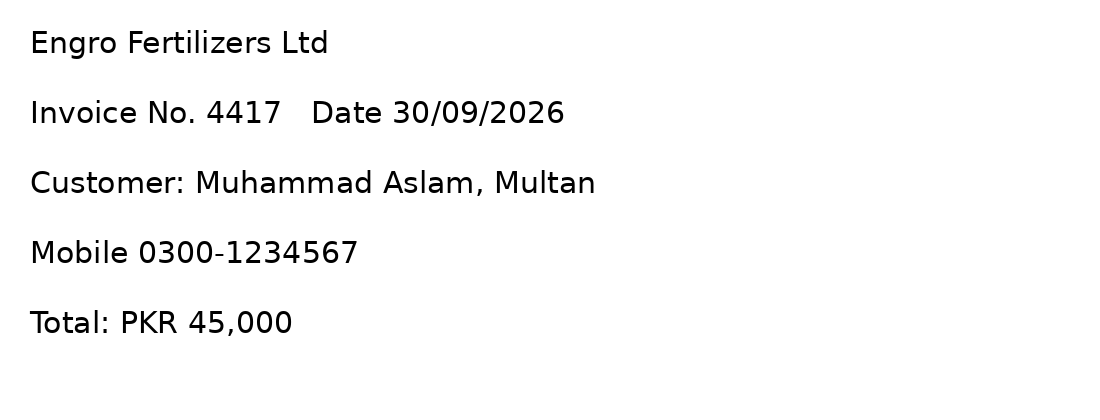

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


OCR output: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
Corrected output: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER before correction: 0.000
CER after correction:  0.000


In [26]:
import re
import torch
import easyocr

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from matplotlib import font_manager

# Use a scalable font available through Matplotlib.
font_path = font_manager.findfont("DejaVu Sans")
font = ImageFont.truetype(font_path, 30)
print("Font used:", font_path)

# Create the synthetic invoice image.
image = Image.new("RGB", (1100, 420), "white")
draw = ImageDraw.Draw(image)

lines = [
    "Engro Fertilizers Ltd",
    "Invoice No. 4417   Date 30/09/2026",
    "Customer: Muhammad Aslam, Multan",
    "Mobile 0300-1234567",
    "Total: PKR 45,000"
]

for row, line in enumerate(lines):
    draw.text((30, 25 + 70 * row), line, fill="black", font=font)

image.save("invoice.png")
display(image)

# Calculate character-level edit distance.
def levenshtein(a, b):
    distances = list(range(len(b) + 1))

    for i, char_a in enumerate(a, start=1):
        previous_diagonal = distances[0]
        distances[0] = i

        for j, char_b in enumerate(b, start=1):
            old_distance = distances[j]
            distances[j] = min(
                distances[j] + 1,
                distances[j - 1] + 1,
                previous_diagonal + (char_a != char_b)
            )
            previous_diagonal = old_distance

    return distances[-1]


def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)


def fix_ocr(text):
    # Correct O/0 and I/1 confusions inside numbers.
    text = re.sub(
        r"(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)",
        "0",
        text
    )
    text = re.sub(r"(?<=\d)[lI](?=\d)", "1", text)

    # Correct "N0." when zero is used in place of the letter O.
    text = re.sub(r"\bN0\.", "No.", text)

    # Correct a comma read instead of the slash in a date like 30,09/2026.
    text = re.sub(r"(?<=\d),(?=\d{2}/\d{4})", "/", text)

    return text


# Run EasyOCR.
reader = easyocr.Reader(
    ["en"],
    gpu=torch.cuda.is_available(),
    verbose=False
)

ocr_text = "\n".join(
    text for _, text, confidence in reader.readtext("invoice.png")
)

normalize_text = lambda text: " ".join(text.split())

reference_text = normalize_text(" ".join(lines))
raw_text = normalize_text(ocr_text)
corrected_text = normalize_text(fix_ocr(ocr_text))

print("OCR output:", raw_text)
print("Corrected output:", corrected_text)
print(f"CER before correction: {cer(reference_text, raw_text):.3f}")
print(f"CER after correction:  {cer(reference_text, corrected_text):.3f}")

### Part 5: OCR result

EasyOCR read the clean, typed invoice correctly. CER was 0.000 before and after correction, so the repair rules did not need to change the text. A real phone photo could be harder to read because of blur, shadows, skew, or lower resolution. The `pin_memory` warning appeared because this notebook ran on CPU; it did not stop OCR.

## Part 6: Image and Text Case Record

I will combine the Week 6 image model with text evidence in one case record. Before extracting or logging text, I will mask possible personal identifiers.

In [27]:
import re

def mask_pii(text):
    text = re.sub(PATTERNS["cnic"], "[CNIC]", text)
    text = re.sub(PATTERNS["mobile"], "[PHONE]", text)
    text = re.sub(PATTERNS["email"], "[EMAIL]", text)
    return text

sample_note = (
    "CNIC 35202-1234567-1, call 0300-1234567, "
    "email patient@example.com"
)

print(mask_pii(sample_note))

CNIC [CNIC], call [PHONE], email [EMAIL]


In [28]:
from pathlib import Path
import torch
import torch.nn as nn
from torchvision import models

# Find the attached checkpoint file.
matches = list(Path("/kaggle/input").rglob("week6_model.pt"))

if not matches:
    raise FileNotFoundError(
        "week6_model.pt was not found. Check that the week6-model "
        "dataset is attached to this notebook."
    )

W6_PATH = matches[0]
print("Checkpoint found:", W6_PATH)

# Load the checkpoint on CPU.
checkpoint = torch.load(
    W6_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", list(checkpoint.keys()))
print("Backbone:", checkpoint["backbone"])
print("Classes:", checkpoint["classes"])
print("Image size:", checkpoint["img_size"])
print("Grayscale:", checkpoint["grayscale"])

# Rebuild the same model architecture used in Week 6.
backbone = checkpoint["backbone"]
number_of_classes = len(checkpoint["classes"])

if backbone.startswith("resnet"):
    image_model = getattr(models, backbone)(weights=None)
    image_model.fc = nn.Linear(
        image_model.fc.in_features,
        number_of_classes
    )
elif backbone == "efficientnet_b0":
    image_model = models.efficientnet_b0(weights=None)
    image_model.classifier[1] = nn.Linear(
        image_model.classifier[1].in_features,
        number_of_classes
    )
else:
    raise ValueError(f"Unsupported backbone in checkpoint: {backbone}")

image_model.load_state_dict(checkpoint["state_dict"])
image_model.eval()

classes = checkpoint["classes"]

print("Model loaded successfully.")
print("Class labels:", classes)

Checkpoint found: /kaggle/input/datasets/muhammadhaissam/week6-model/week6_model.pt
Checkpoint keys: ['state_dict', 'classes', 'backbone', 'img_size', 'grayscale']
Backbone: resnet18
Classes: ['NORMAL', 'PNEUMONIA']
Image size: 224
Grayscale: True
Model loaded successfully.
Class labels: ['NORMAL', 'PNEUMONIA']


Test image: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg


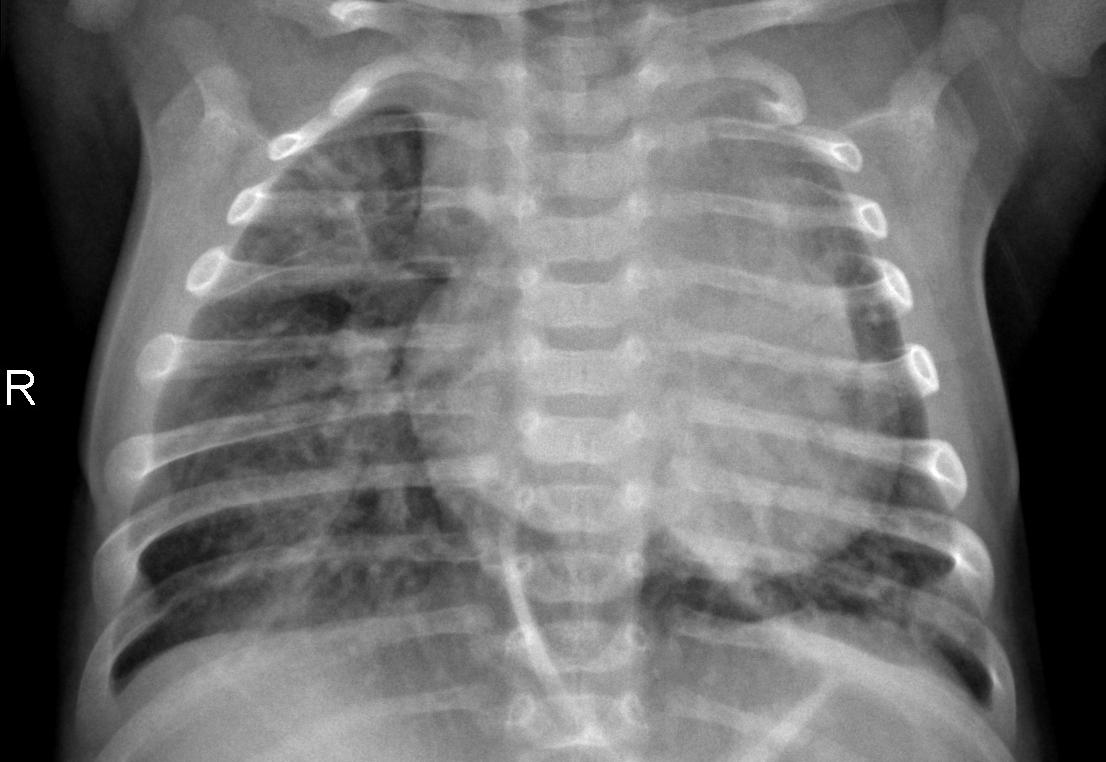

Model probabilities: {'NORMAL': 0.007, 'PNEUMONIA': 0.993}
Predicted class: PNEUMONIA


In [29]:
from pathlib import Path
from PIL import Image
from IPython.display import display
from torchvision import transforms
import torch.nn.functional as F

# Locate the test folder containing NORMAL and PNEUMONIA images.
test_dirs = [
    folder for folder in Path("/kaggle/input").rglob("test")
    if (folder / "NORMAL").is_dir()
    and (folder / "PNEUMONIA").is_dir()
]

if not test_dirs:
    raise FileNotFoundError(
        "Could not find a test folder containing NORMAL and PNEUMONIA."
    )

test_dir = test_dirs[0]
pneumonia_files = sorted(
    path for path in (test_dir / "PNEUMONIA").iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if not pneumonia_files:
    raise FileNotFoundError("No PNEUMONIA test images were found.")

image_path = pneumonia_files[0]
print("Test image:", image_path)
display(Image.open(image_path))

# Prepare the image using the checkpoint's grayscale setting and size.
image_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3)
    if checkpoint["grayscale"]
    else transforms.Lambda(lambda image: image),
    transforms.Resize((checkpoint["img_size"], checkpoint["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image = Image.open(image_path).convert("RGB")
image_tensor = image_transform(image).unsqueeze(0)

# Get the model's class probabilities.
with torch.no_grad():
    logits = image_model(image_tensor)
    probabilities = F.softmax(logits, dim=1)[0]

image_probabilities = {
    class_name: round(float(probability), 3)
    for class_name, probability in zip(classes, probabilities)
}

print("Model probabilities:", image_probabilities)
print("Predicted class:", classes[int(probabilities.argmax())])

In [30]:
import json

# Fictional example note for the assignment.
synthetic_note = (
    "CNIC 35202-1234567-1, mobile 0300-1234567, "
    "email patient@example.com. The note mentions fever and cough."
)

def text_evidence(note):
    safe_note = mask_pii(note)
    doc = nlp(safe_note)

    urgent_terms = [
        term for term in ["fever", "breath", "cough", "chest pain", "spreading", "crack"]
        if term in safe_note.lower()
    ]

    return {
        "masked_note": safe_note,
        "entities": [(entity.text, entity.label_) for entity in doc.ents],
        "extracted_fields": extract_fields(safe_note),
        "urgent_terms": urgent_terms
    }

def create_case_record(image_path, note, threshold=0.5):
    safe_text_evidence = text_evidence(note)
    pneumonia_score = image_probabilities["PNEUMONIA"]

    reasons = []

    if pneumonia_score >= threshold:
        reasons.append(
            f"Image model flagged PNEUMONIA "
            f"(model score: {pneumonia_score:.3f})"
        )

    if safe_text_evidence["urgent_terms"]:
        reasons.append(
            "Note mentions: " + ", ".join(safe_text_evidence["urgent_terms"])
        )

    return {
        "image": str(image_path),
        "image_probabilities": image_probabilities,
        "text_evidence": safe_text_evidence,
        "review_reasons": reasons,
        "case_status": (
            "REFER FOR HUMAN REVIEW" if reasons
            else "NO AUTOMATED FLAG"
        ),
        "disclaimer": (
            "Educational demonstration only. Model output is not a diagnosis; "
            "a qualified clinician must review the case."
        )
    }

case_record = create_case_record(image_path, synthetic_note)
print(json.dumps(case_record, indent=2))

{
  "image": "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg",
  "image_probabilities": {
    "NORMAL": 0.007,
    "PNEUMONIA": 0.993
  },
  "text_evidence": {
    "masked_note": "CNIC [CNIC], mobile [PHONE], email [EMAIL]. The note mentions fever and cough.",
    "entities": [
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "extracted_fields": {},
    "urgent_terms": [
      "fever",
      "cough"
    ]
  },
  "review_reasons": [
    "Image model flagged PNEUMONIA (model score: 0.993)",
    "Note mentions: fever, cough"
  ],
  "case_status": "REFER FOR HUMAN REVIEW",
  "disclaimer": "Educational demonstration only. Model output is not a diagnosis; a qualified clinician must review the case."
}


### Part 6: Case record interpretation

The case record combines image-model output with text evidence. The image model assigned this test image a PNEUMONIA score of 0.993. The fictional note also mentioned fever and cough. Since both signals triggered the review rule, the case was marked “REFER FOR HUMAN REVIEW.”

The note was masked before text analysis: the CNIC, phone number, and email were replaced with placeholders. spaCy incorrectly labeled “CNIC” as an organization. This is a false positive. It does not expose the masked identifier, but it could create inaccurate entity information in a later summary.

If image and text evidence disagree, the system should not automatically treat the case as normal or make a diagnosis. It should flag the disagreement for review by a qualified clinician, who can check the image, note, and other relevant information. This notebook is an educational demonstration, not a medical tool.